# Day 11 – Classification using Logistic Regression and Decision Tree

**Objective:** Train two classification models and compare their accuracy.

**Dataset:** Scikit-learn Breast Cancer Wisconsin dataset, saved locally as CSV. This is for educational practice only, not medical diagnosis.

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

## 2. Load and inspect the dataset

In [2]:
df = pd.read_csv("../data/breast_cancer_classification.csv")
print("Shape:", df.shape)
display(df.head())
print(df["target_label"].value_counts())

Shape: (569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,target_label
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant


target_label
benign       357
malignant    212
Name: count, dtype: int64


## 3. Define features and target

In [3]:
X = df.drop(columns=["target", "target_label"])
y = df["target"]

## 4. Split into training and testing data

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 455
Testing records: 114


## 5. Train Logistic Regression

In [5]:
logistic_model = Pipeline([("scaler", StandardScaler()), ("classifier", LogisticRegression(max_iter=5000))])
logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
print(f"Logistic Regression Accuracy: {logistic_accuracy:.2%}")

Logistic Regression Accuracy: 98.25%


## 6. Train Decision Tree

In [6]:
tree_model = DecisionTreeClassifier(random_state=42, max_depth=4)
tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_predictions)
print(f"Decision Tree Accuracy: {tree_accuracy:.2%}")

Decision Tree Accuracy: 93.86%


## 7. Compare accuracy

In [7]:
comparison = pd.DataFrame({"Model": ["Logistic Regression", "Decision Tree"], "Accuracy": [logistic_accuracy, tree_accuracy]})
display(comparison)
comparison.to_csv("../outputs/accuracy_comparison.csv", index=False)

,Model,Accuracy
0,Logistic Regression,0.982456
1,Decision Tree,0.938596


## 8. Plot the comparison

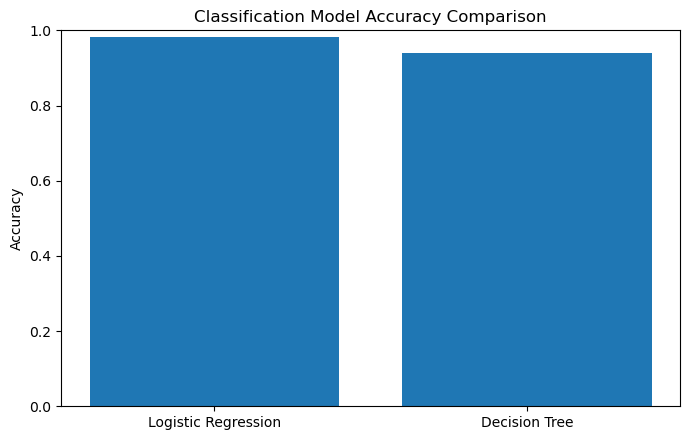

In [8]:
plt.figure(figsize=(7, 4.5))
plt.bar(comparison["Model"], comparison["Accuracy"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Classification Model Accuracy Comparison")
plt.tight_layout()
plt.show()

## 9. Review classification reports

In [9]:
print("Logistic Regression report:")
print(classification_report(y_test, logistic_predictions, target_names=["malignant", "benign"]))
print("Decision Tree report:")
print(classification_report(y_test, tree_predictions, target_names=["malignant", "benign"]))

Logistic Regression report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Decision Tree report:
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



## Observations
Compare the accuracy values shown above. Accuracy depends on the chosen dataset and split. This educational exercise is not a medical diagnostic tool; accuracy alone is insufficient for clinical decisions.

## Conclusion
This notebook demonstrates a classification workflow: load data, select features and target, split data, train two models, compare accuracy, and review classification reports.